In [ ]:
# Experiment 4B: Logistic Regression for Multiclass Classification

In [ ]:
# Import the Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
# Load the Iris Dataset
df = pd.read_csv("iris.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

First Five Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Shape: (150, 5)


In [ ]:
# Explore the Dataset and Check Missing Values
print("Dataset Information:")
df.info()

print("\nFirst Five Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Description:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

First Five Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [ ]:
## Handle Missing Values and Prepare the Dataset
# Remove rows containing missing values
df = df.dropna()

# Separate input features and target variable
X = df.drop(columns=['species'])
y = df['species']

# Encode species names into numerical labels
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Input Features:")
print(X.head())

print("\nEncoded Target Classes:")
print(encoder.classes_)

print("\nMissing values handled and target encoded.")

Input Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Encoded Target Classes:
['setosa' 'versicolor' 'virginica']

Missing values handled and target encoded.


In [ ]:
# Scale the Input Features
# Standardize the input features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Input Features:")
print(X_scaled[:5])

Scaled Input Features:
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [ ]:
# Split the Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)


In [ ]:
## Create and Train the Logistic Regression Model
# Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
## Predict the iris Flower Species
# Predict species for the test dataset
y_pred = model.predict(X_test)

print("Predicted Species:")
print(encoder.inverse_transform(y_pred))

Predicted Species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [ ]:
## Predict Class Probabilities
# Predict probabilities for each Iris species
y_prob = model.predict_proba(X_test)

# Display probabilities
probability_df = pd.DataFrame(
    y_prob,
    columns=encoder.classes_
)

print("Predicted Probabilities for Each Species:")
print(probability_df.head())

Predicted Probabilities for Each Species:
     setosa  versicolor     virginica
0  0.979651    0.020349  3.447941e-07
1  0.003779    0.370104  6.261171e-01
2  0.148457    0.842803  8.739844e-03
3  0.094181    0.895843  9.976629e-03
4  0.989096    0.010904  1.608431e-07


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


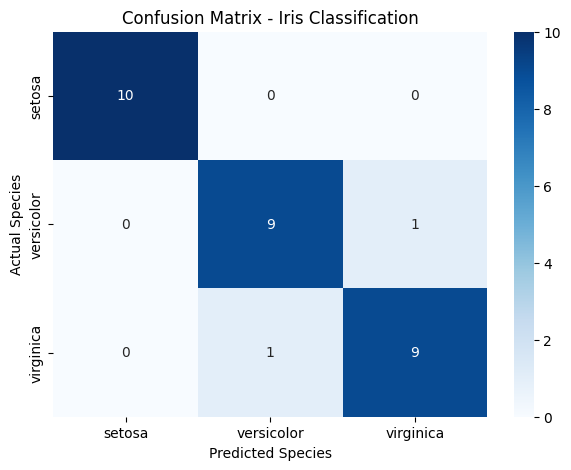

In [ ]:
## Display the Confusion Matrix
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display the confusion matrix as a heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - Iris Classification")
plt.show()

In [ ]:
# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333


In [ ]:
# Display detailed classification results
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
print("Conclusion:")
print("Multiclass Logistic Regression was successfully implemented")
print("to classify Iris flowers into three species.")
print("The model was evaluated using accuracy, precision, recall, and F1 score.")

Conclusion:
Multiclass Logistic Regression was successfully implemented
to classify Iris flowers into three species.
The model was evaluated using accuracy, precision, recall, and F1 score.
